# Lecture 1: First Forward Problem (with solutions)

**Forward problem:** given the state of a physical system now, predict its state a moment later,

$$u(t) \;\longmapsto\; u(t + \Delta t),$$

then apply the model repeatedly to predict further into the future (an *autoregressive rollout*).

1. **Heat equation**: a small dataset we build from the exact solution.
2. **BubbleML**: simulations of pool boiling.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, TensorDataset, ConcatDataset, DataLoader

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print("Using device:", device)

torch.manual_seed(0)
rng = np.random.default_rng(0)

Using device: cpu


---
## Part 1: The 2D Heat Equation

$$\frac{\partial u}{\partial t} = \alpha \nabla^2 u \quad \text{on } [0,1]^2, \qquad u = 0 \text{ on the boundary}$$

By separation of variables, the solution is a sum of sine modes, each decaying at its own rate:

$$u(x, y, t) = \sum_{m,n} a_{mn} \, \sin(m\pi x)\,\sin(n\pi y)\, e^{-\alpha \pi^2 (m^2 + n^2)\, t}$$

Higher-frequency modes decay faster. We pick random coefficients $a_{mn}$ to get many different
initial conditions, and evaluate this formula on a grid to get our dataset. No solver needed.

In [2]:
N = 48            # grid points per side
alpha = 1.0       # diffusivity
dt = 5e-4         # time between saved frames
T = 100           # frames per trajectory
K = 6             # use modes m, n = 1..K

x = np.linspace(0, 1, N)
X, Y = np.meshgrid(x, x)

def heat_trajectory():
    u = np.zeros((T + 1, N, N))
    t = np.arange(T + 1)[:, None, None] * dt
    for m in range(1, K + 1):
        for n in range(1, K + 1):
            a = rng.normal() / (m**2 + n**2)     # smaller amplitude for higher frequencies
            u += a * np.sin(m * np.pi * X) * np.sin(n * np.pi * Y) * np.exp(-alpha * np.pi**2 * (m**2 + n**2) * t)
    return u

heat_train = np.stack([heat_trajectory() for _ in range(100)]).astype(np.float32)
heat_test = np.stack([heat_trajectory() for _ in range(20)]).astype(np.float32)
print("dataset shape (trajectory, time, y, x):", heat_train.shape)

dataset shape (trajectory, time, y, x): (100, 101, 48, 48)


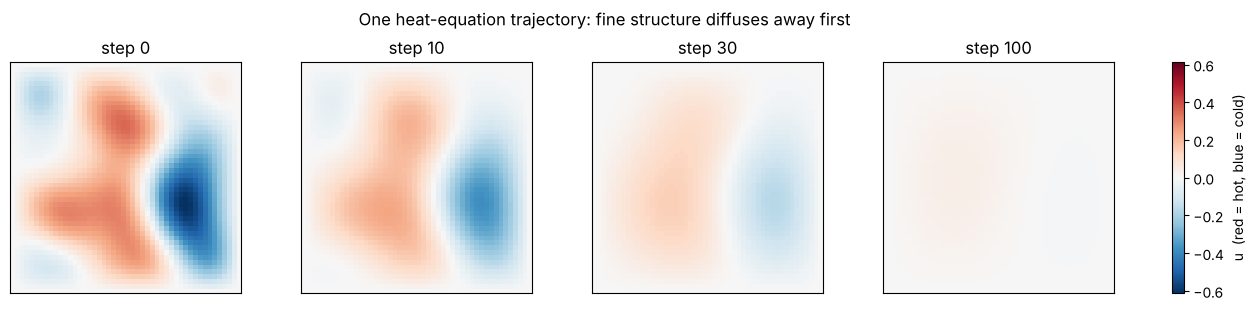

In [3]:
steps = [0, 10, 30, 100]
vmax = np.abs(heat_train[0, 0]).max()
fig, axes = plt.subplots(1, len(steps), figsize=(13, 3), layout="constrained")
for ax, s in zip(axes, steps):
    im = ax.imshow(heat_train[0, s], cmap="RdBu_r", vmin=-vmax, vmax=vmax, origin="lower")
    ax.set_title(f"step {s}"); ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(im, ax=axes, label="u  (red = hot, blue = cold)")
fig.suptitle("One heat-equation trajectory: fine structure diffuses away first")
plt.show()

### Setting up the forward problem

Each consecutive pair of frames $(u_n, u_{n+1})$ is one training example: input $u_n$, target $u_{n+1}$.

In [4]:
def to_pairs(trajs):
    inputs = trajs[:, :-1].reshape(-1, 1, N, N)    # (samples, channels, y, x)
    targets = trajs[:, 1:].reshape(-1, 1, N, N)
    return TensorDataset(torch.from_numpy(inputs), torch.from_numpy(targets))

heat_loader = DataLoader(to_pairs(heat_train), batch_size=64, shuffle=True)
print("training pairs:", len(heat_loader.dataset))

training pairs: 10000


### Model: a small CNN

Convolutions are *local* and *translation invariant*, like the physics of diffusion.
The network predicts the **change** from $u_n$ to $u_{n+1}$, which we add back to the input.

In [5]:
class SmallCNN(nn.Module):
    def __init__(self, in_channels=1, hidden=32):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_channels, hidden, 3, padding=1), nn.GELU(),
            nn.Conv2d(hidden, hidden, 3, padding=1), nn.GELU(),
            nn.Conv2d(hidden, hidden, 3, padding=1), nn.GELU(),
            nn.Conv2d(hidden, 1, 3, padding=1),
        )

    def forward(self, x):
        # x[:, :1] is the current field (the first input channel); predict its change
        return x[:, :1] + self.net(x)

def train(model, loader, epochs, lr=1e-3):
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    for epoch in range(epochs):
        total = 0.0
        for inputs, targets in loader:
            inputs, targets = inputs.float().to(device), targets.float().to(device)   # MPS needs float32
            loss = F.mse_loss(model(inputs), targets)
            optimizer.zero_grad(); loss.backward(); optimizer.step()
            total += loss.item()
        print(f"epoch {epoch + 1:2d}   loss {total / len(loader):.2e}")
    return model

heat_model = train(SmallCNN(in_channels=1), heat_loader, epochs=10)

epoch  1   loss 9.49e-06


epoch  2   loss 3.86e-06


epoch  3   loss 3.22e-06


epoch  4   loss 2.79e-06


epoch  5   loss 2.46e-06


epoch  6   loss 2.34e-06


epoch  7   loss 2.10e-06


epoch  8   loss 1.84e-06


epoch  9   loss 1.33e-06


epoch 10   loss 6.92e-07


### Rollout: using the model as a simulator

Start from the first frame of a test trajectory and feed each prediction back in as the next input.
Each step adds a little error, and those errors build up.

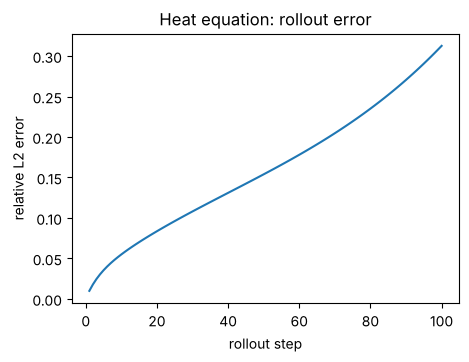

In [6]:
def relative_error(pred, true):
    return np.linalg.norm(pred - true) / np.linalg.norm(true)

heat_model.eval()
errors = []
for traj in heat_test:
    u = torch.from_numpy(traj[0]).reshape(1, 1, N, N).to(device)
    preds = []
    with torch.no_grad():
        for n in range(T):
            u = heat_model(u)
            preds.append(u.cpu().numpy()[0, 0])
    errors.append([relative_error(preds[n], traj[n + 1]) for n in range(T)])
heat_rollout = np.array(preds)       # rollout of the last test trajectory, kept for plotting

plt.figure(figsize=(5, 3.5))
plt.plot(np.arange(1, T + 1), np.mean(errors, axis=0))
plt.xlabel("rollout step"); plt.ylabel("relative L2 error"); plt.title("Heat equation: rollout error")
plt.show()

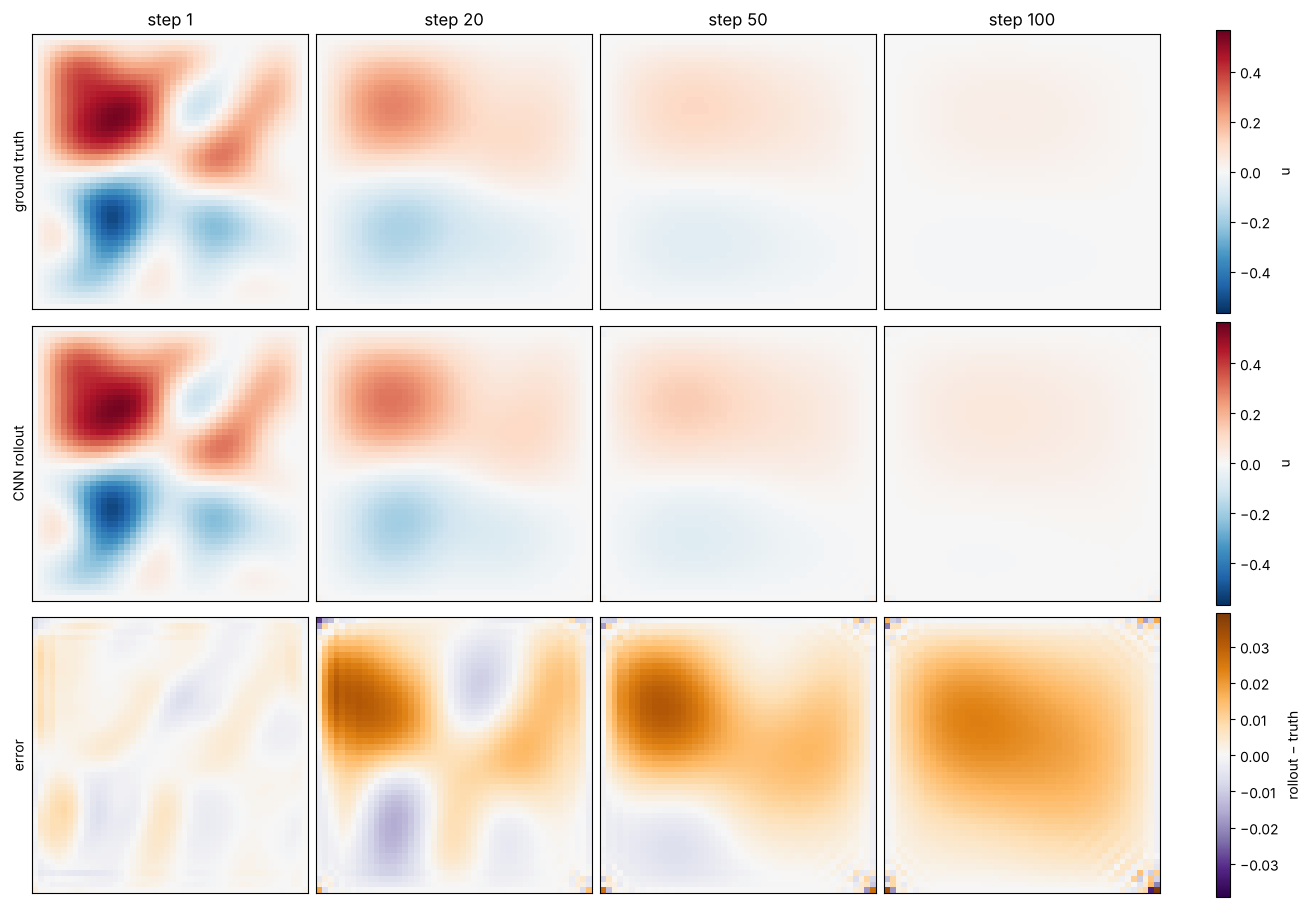

In [7]:
truth = heat_test[-1]
steps = [1, 20, 50, 100]
vmax = np.abs(truth[0]).max()
error = heat_rollout - truth[1:]      # CNN rollout minus ground truth
emax = np.abs(error).max()           # the error is much smaller than the field, so it gets its own color scale
rows = [(truth[1:], "ground truth", "RdBu_r", vmax, "u"),
        (heat_rollout, "CNN rollout", "RdBu_r", vmax, "u"),
        (error, "error", "PuOr_r", emax, "rollout − truth")]
fig, axes = plt.subplots(3, len(steps), figsize=(13, 9), layout="constrained")
for row, (data, name, cmap, lim, label) in enumerate(rows):
    for k, s in enumerate(steps):
        im = axes[row, k].imshow(data[s - 1], cmap=cmap, vmin=-lim, vmax=lim, origin="lower")
        axes[row, k].set_xticks([]); axes[row, k].set_yticks([])
        axes[0, k].set_title(f"step {s}")
    axes[row, 0].set_ylabel(name)
    fig.colorbar(im, ax=axes[row, :], label=label)
plt.show()

---
## Part 2: BubbleML Pool Boiling

[BubbleML](https://github.com/HPCForge/BubbleML) is a dataset of multiphase boiling simulations.
A heater on the bottom wall boils the liquid; vapor bubbles form, grow, detach and rise.

We use the small downsampled *subcooled pool boiling* examples from the BubbleML repo:
three simulations with heater (wall) temperatures of 100, 103 and 106 °C.

In [8]:
import os
import urllib.request
import h5py

DATA_DIR = "../data/bubbleml"
FILES = ["Twall-100.hdf5", "Twall-103.hdf5", "Twall-106.hdf5"]
URL = "https://raw.githubusercontent.com/HPCForge/BubbleML/main/examples/"

os.makedirs(DATA_DIR, exist_ok=True)
for f in FILES:
    path = os.path.join(DATA_DIR, f)
    if not os.path.exists(path):
        print("downloading", f)
        urllib.request.urlretrieve(URL + f, path)

### What's in a simulation file?

In [9]:
sim = h5py.File(os.path.join(DATA_DIR, "Twall-100.hdf5"), "r")

for key in ["temperature", "velx", "vely", "pressure", "dfun"]:
    field = sim[key][:]
    print(f"{key:12s} shape {field.shape}   dtype {field.dtype}   range [{field.min():7.3f}, {field.max():7.3f}]")

params = {k.decode().strip(): v for k, v in sim["real-runtime-params"][:]}
print("\nReynolds number:", 1 / params["ins_invreynolds"])
print("domain: x in", (params["xmin"], params["xmax"]), " y in", (params["ymin"], params["ymax"]))

temperature  shape (201, 48, 48)   dtype float64   range [ -0.001,   0.988]
velx         shape (201, 48, 48)   dtype float64   range [ -7.083,   8.013]
vely         shape (201, 48, 48)   dtype float64   range [ -4.669,   5.915]
pressure     shape (201, 48, 48)   dtype float64   range [-155.289, 141.335]
dfun         shape (201, 48, 48)   dtype float64   range [-12.177,   1.318]

Reynolds number: 238.0952380952381
domain: x in (np.float64(-6.0), np.float64(6.0))  y in (np.float64(0.0), np.float64(12.0))


**How is this different from an image or a sequence of tokens?**

* **Channels are physical fields** such as temperature, two velocity components, pressure,
  and `dfun` (signed distance to the bubble surface: > 0 in vapor, < 0 in liquid).
  They have different units and very different ranges.
* **Values are continuous physical quantities** (64 bit floats), not pixel intensities 0–255 or token IDs from a vocabulary.
* **There's a time axis.** Frames are ordered and strongly correlated, like tokens in a sentence, but each
  "token" is an entire 2D field. Shuffling frames destroys the physics.
* **The grid is a physical domain** with real extents and boundary conditions (the heater is the bottom wall).
* **Metadata matters.** Each file records simulation parameters such as the Reynolds number.

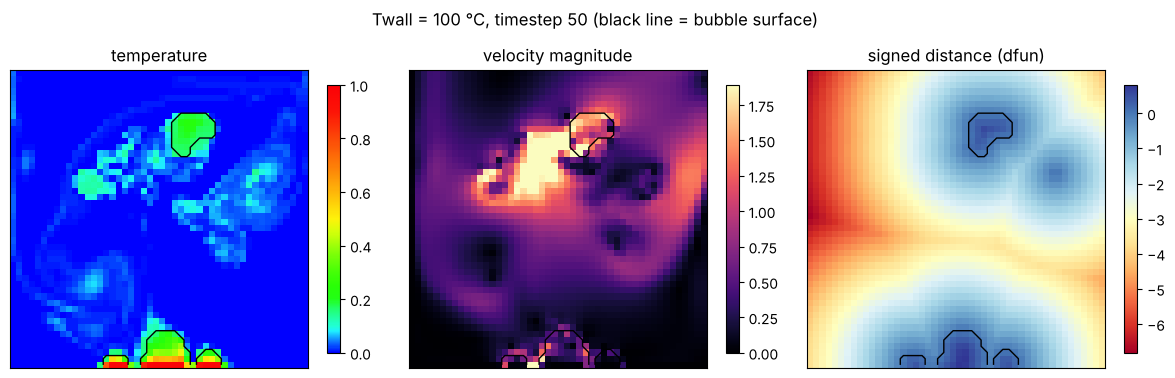

In [10]:
from matplotlib.colors import LinearSegmentedColormap

# temperature colormap from https://github.com/therml-ai/boiling-viz (for nondimensional temperature in [0, 1])
temp_cmap = LinearSegmentedColormap.from_list("temp_green", list(zip(
    [0.0, 0.02, 0.04, 0.06, 0.08, 0.1, 0.134, 0.167, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
    ["#0000FF", "#0443FF", "#0E7AFF", "#16B4FF", "#1FF1FF", "#21FFD3", "#22FF9B", "#22FF67", "#22FF15", "#29FF06",
     "#45FF07", "#6DFF08", "#9EFF09", "#D4FF0A", "#FEF30A", "#FEB709", "#FD7D08", "#FC4908", "#FC1407", "#FB0007"])))

temp = sim["temperature"][:]
speed = np.sqrt(sim["velx"][:]**2 + sim["vely"][:]**2)
dfun = sim["dfun"][:]

t = 50
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
panels = [(temp[t], "temperature", temp_cmap, 0, 1),
          (speed[t], "velocity magnitude", "magma", 0, np.percentile(speed, 99)),
          (dfun[t], "signed distance (dfun)", "RdYlBu", None, None)]
for ax, (img, title, cmap, vmin, vmax) in zip(axes, panels):
    im = ax.imshow(img, cmap=cmap, vmin=vmin, vmax=vmax, origin="lower")
    ax.contour(dfun[t] > 0, levels=[0.5], colors="black", linewidths=1)   # bubble surface
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(im, ax=ax, shrink=0.8)
plt.suptitle(f"Twall = 100 °C, timestep {t} (black line = bubble surface)")
plt.tight_layout(); plt.show()

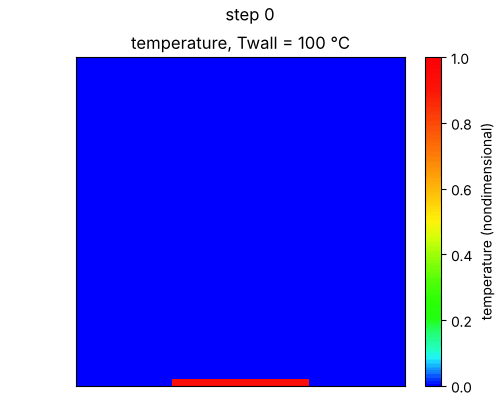

In [11]:
def animate(fields, titles, filename, cmap=temp_cmap, fps=10):
    # side-by-side animation of 2D fields over time, saved as a GIF; each field has shape (time, y, x)
    fig, axes = plt.subplots(1, len(fields), figsize=(4 * len(fields) + 1, 4), layout="constrained")
    axes = np.atleast_1d(axes)
    ims = []
    for ax, f, title in zip(axes, fields, titles):
        ims.append(ax.imshow(f[0], cmap=cmap, vmin=0, vmax=1, origin="lower"))
        ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(ims[0], ax=axes, label="temperature (nondimensional)")
    label = fig.suptitle("step 0")
    def update(i):
        for im, f in zip(ims, fields):
            im.set_data(f[i])
        label.set_text(f"step {i}")
        return ims
    anim = FuncAnimation(fig, update, frames=len(fields[0]))
    anim.save(filename, writer=PillowWriter(fps=fps), dpi=100)
    plt.close(fig)
    return Image(filename=filename)

animate([temp], ["temperature, Twall = 100 °C"], "bubbleml_temperature.gif")

### The forward problem for boiling

Given **temperature and velocity** at step $n$, predict **temperature** at step $n+1$.

$$(T_n,\; v_{x,n},\; v_{y,n}) \;\longmapsto\; T_{n+1}$$

We train on the 100 °C and 106 °C simulations and test on 103 °C, a condition the model never sees.

In [12]:
class HDF5Dataset(Dataset):
    def __init__(self, filename):
        self.data = h5py.File(filename, "r")
        self.timesteps = self.data["temperature"].shape[0]

    def __len__(self):
        return self.timesteps - 1

    def __getitem__(self, idx):
        # input: temperature, x-velocity, y-velocity at step idx.  target: temperature at step idx + 1
        input = torch.stack([torch.from_numpy(self.data[k][idx]) for k in ["temperature", "velx", "vely"]])
        label = torch.from_numpy(self.data["temperature"][idx + 1]).unsqueeze(0)
        return input, label

train_files = ["Twall-100.hdf5", "Twall-106.hdf5"]
train_dataset = ConcatDataset([HDF5Dataset(os.path.join(DATA_DIR, f)) for f in train_files])
test_dataset = HDF5Dataset(os.path.join(DATA_DIR, "Twall-103.hdf5"))

bubble_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
print("training pairs:", len(train_dataset), "  test pairs:", len(test_dataset))

training pairs: 400   test pairs: 200


In [13]:
bubble_model = train(SmallCNN(in_channels=3, hidden=64), bubble_loader, epochs=40)

epoch  1   loss 2.82e-03


epoch  2   loss 2.28e-03


epoch  3   loss 2.10e-03


epoch  4   loss 1.87e-03


epoch  5   loss 1.73e-03


...

epoch 36   loss 1.11e-03


epoch 37   loss 1.11e-03


epoch 38   loss 1.10e-03


epoch 39   loss 1.10e-03


epoch 40   loss 1.08e-03


### Rollout on the unseen 103 °C simulation

We only predict temperature, so at every step we take the velocity from the simulation
and the temperature from the model's previous prediction.

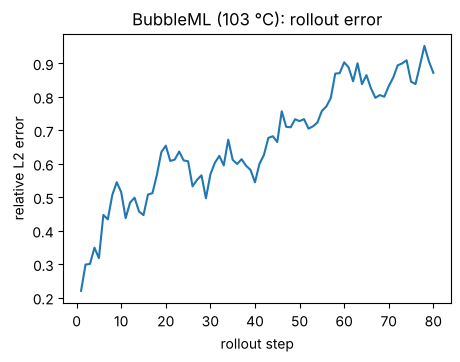

In [14]:
test = test_dataset.data
true_temp = test["temperature"][:].astype(np.float32)
vel = np.stack([test["velx"][:], test["vely"][:]], axis=1).astype(np.float32)   # (time, 2, y, x)

start, steps = 20, 80
bubble_model.eval()
temp_pred = torch.from_numpy(true_temp[start]).reshape(1, 1, 48, 48).to(device)
preds = []
with torch.no_grad():
    for n in range(start, start + steps):
        velocity = torch.from_numpy(vel[n]).unsqueeze(0).to(device)
        temp_pred = bubble_model(torch.cat([temp_pred, velocity], dim=1))
        preds.append(temp_pred.cpu().numpy()[0, 0])
preds = np.array(preds)
truth = true_temp[start + 1 : start + 1 + steps]

plt.figure(figsize=(5, 3.5))
plt.plot(np.arange(1, steps + 1), [relative_error(p, t) for p, t in zip(preds, truth)])
plt.xlabel("rollout step"); plt.ylabel("relative L2 error"); plt.title("BubbleML (103 °C): rollout error")
plt.show()

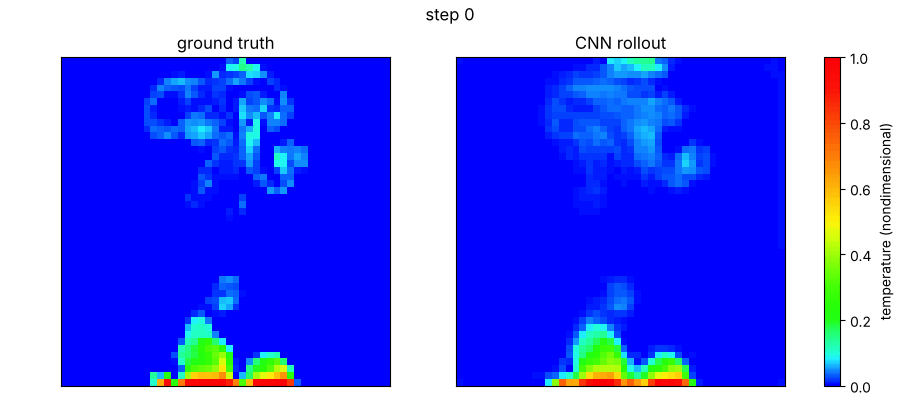

In [15]:
animate([truth, preds], ["ground truth", "CNN rollout"], "bubbleml_rollout.gif")

**What to notice:** the error grows much faster than for the heat equation, and the prediction smears out the sharp
bubble boundaries. Keeping long autoregressive rollouts accurate and stable is an open problem.

---
## Exercises

1. **Add the bubble surface as an input.** Include `dfun` as a fourth input channel in `HDF5Dataset`
   (and in the rollout). Does the rollout improve? 
2. **Bigger time steps.** Train the heat equation model to predict 5 frames ahead ($u_n \to u_{n+5}$). Compare its rollout
   error at the same physical time with the 1-step model's. Fewer steps means fewer chances for error to build up but is each step harder?
3. **Unseen frequencies.** Train the heat model with `K = 3` and test on data made with `K = 6`. What goes wrong, and why?
4. **Frozen velocity.** In the BubbleML rollout, keep the velocity fixed at its value at `start` instead of reading it from
   the simulation. How quickly does the prediction fall apart?

---
## Solutions

### Exercise 1: the bubble surface as an input

`dfun` is the signed distance to the bubble surface. We add it as a fourth input channel, train the same model, and roll out on 103 °C
with velocity and `dfun` taken from the simulation at every step.

epoch  1   loss 7.98e-03


epoch  2   loss 2.44e-03


epoch  3   loss 2.29e-03


epoch  4   loss 2.17e-03


epoch  5   loss 2.04e-03


...

epoch 37   loss 1.21e-03


epoch 38   loss 1.21e-03


epoch 39   loss 1.21e-03


epoch 40   loss 1.20e-03


step  1   T, vx, vy: 0.220   T, vx, vy, dfun: 0.215
step  5   T, vx, vy: 0.318   T, vx, vy, dfun: 0.306
step 10   T, vx, vy: 0.515   T, vx, vy, dfun: 0.517
step 20   T, vx, vy: 0.654   T, vx, vy, dfun: 0.550
step 40   T, vx, vy: 0.544   T, vx, vy, dfun: 0.514
step 80   T, vx, vy: 0.872   T, vx, vy, dfun: 0.517


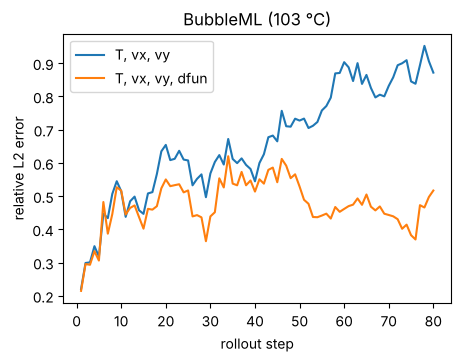

In [16]:
class HDF5DatasetDfun(HDF5Dataset):
    def __getitem__(self, idx):
        input = torch.stack([torch.from_numpy(self.data[k][idx]) for k in ["temperature", "velx", "vely", "dfun"]])
        label = torch.from_numpy(self.data["temperature"][idx + 1]).unsqueeze(0)
        return input, label

torch.manual_seed(0)
dfun_loader = DataLoader(ConcatDataset([HDF5DatasetDfun(os.path.join(DATA_DIR, f)) for f in train_files]), batch_size=16, shuffle=True)
dfun_model = train(SmallCNN(in_channels=4, hidden=64), dfun_loader, epochs=40)

def bubble_rollout(model, channels, start=20, steps=80, freeze=False):
    # channels: the given fields after temperature, read from the simulation at step n (or at `start` if freeze)
    model.eval()
    given = np.stack([test[k][:] for k in channels], axis=1).astype(np.float32)     # (time, C, y, x)
    temp_pred = torch.from_numpy(true_temp[start]).reshape(1, 1, 48, 48).to(device)
    out = []
    with torch.no_grad():
        for n in range(start, start + steps):
            g = torch.from_numpy(given[start if freeze else n]).unsqueeze(0).to(device)
            temp_pred = model(torch.cat([temp_pred, g], dim=1))
            out.append(temp_pred.cpu().numpy()[0, 0])
    out = np.array(out)
    return out, np.array([relative_error(p, t) for p, t in zip(out, true_temp[start + 1:start + 1 + steps])])

_, err_base = bubble_rollout(bubble_model, ["velx", "vely"])
_, err_dfun = bubble_rollout(dfun_model, ["velx", "vely", "dfun"])
for s in [1, 5, 10, 20, 40, 80]:
    print(f"step {s:2d}   T, vx, vy: {err_base[s - 1]:.3f}   T, vx, vy, dfun: {err_dfun[s - 1]:.3f}")
plt.figure(figsize=(5, 3.5))
plt.plot(np.arange(1, 81), err_base, label="T, vx, vy")
plt.plot(np.arange(1, 81), err_dfun, label="T, vx, vy, dfun")
plt.xlabel("rollout step"); plt.ylabel("relative L2 error"); plt.title("BubbleML (103 °C)"); plt.legend(); plt.show()

**Answer.** Adding `dfun` changes little in the first 10 steps: the one-step errors are about the same. Later in the rollout it keeps the error lower (in this run about 0.5 at step 80, against 0.9 without it). `dfun` tells the model where the liquid–vapor interface is, which the predicted temperature smears out after a few steps.

Both rollouts read the velocity and `dfun` from the simulation at every step, so the model is given the true interface. A surrogate that runs on its own would have to predict `dfun` as well, which is much harder.

### Exercise 2: bigger time steps

Train on pairs $(u_n, u_{n+5})$ and roll out in steps of 5 frames. Compare with the 1-step model at the same frames (same physical time).

epoch  1   loss 1.05e-04


epoch  2   loss 5.90e-05


epoch  3   loss 4.65e-05


epoch  4   loss 4.03e-05


epoch  5   loss 3.38e-05


...

epoch  7   loss 1.12e-05


epoch  8   loss 5.25e-06


epoch  9   loss 3.70e-06


epoch 10   loss 2.74e-06


frame   5   1-step model (  5 calls): 0.035   5-step model ( 1 calls): 0.027
frame  10   1-step model ( 10 calls): 0.055   5-step model ( 2 calls): 0.030
frame  20   1-step model ( 20 calls): 0.084   5-step model ( 4 calls): 0.041
frame  50   1-step model ( 50 calls): 0.154   5-step model (10 calls): 0.111
frame 100   1-step model (100 calls): 0.313   5-step model (20 calls): 4.918
one-step error, first call:  1-step model 0.0099   5-step model 0.0269


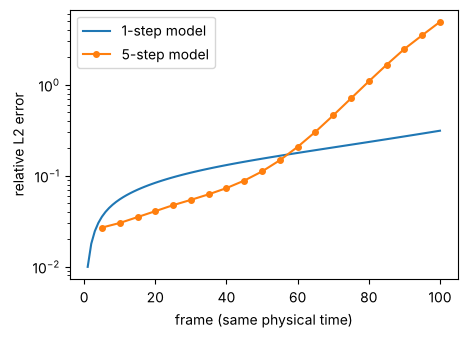

In [17]:
def to_pairs_k(trajs, k):
    return TensorDataset(torch.from_numpy(trajs[:, :-k].reshape(-1, 1, N, N)), torch.from_numpy(trajs[:, k:].reshape(-1, 1, N, N)))

torch.manual_seed(0)
model5 = train(SmallCNN(in_channels=1), DataLoader(to_pairs_k(heat_train, 5), batch_size=64, shuffle=True), epochs=10)

def heat_rollout_errors(model, trajs, k=1):
    # mean relative error at frames k, 2k, ..., T
    model.eval(); errs = []
    with torch.no_grad():
        for traj in trajs:
            u = torch.from_numpy(traj[0]).reshape(1, 1, N, N).to(device); e = []
            for j in range(T // k):
                u = model(u); e.append(relative_error(u.cpu().numpy()[0, 0], traj[(j + 1) * k]))
            errs.append(e)
    return np.mean(errs, axis=0)

err1 = heat_rollout_errors(heat_model, heat_test, 1)
err5 = heat_rollout_errors(model5, heat_test, 5)
frames5 = np.arange(5, T + 1, 5)
for fr in [5, 10, 20, 50, 100]:
    print(f"frame {fr:3d}   1-step model ({fr:3d} calls): {err1[fr - 1]:.3f}   5-step model ({fr // 5:2d} calls): {err5[fr // 5 - 1]:.3f}")
print(f"one-step error, first call:  1-step model {err1[0]:.4f}   5-step model {err5[0]:.4f}")
plt.figure(figsize=(5, 3.5))
plt.semilogy(np.arange(1, T + 1), err1, label="1-step model")
plt.semilogy(frames5, err5, "o-", ms=4, label="5-step model")
plt.xlabel("frame (same physical time)"); plt.ylabel("relative L2 error"); plt.legend(); plt.show()

**Answer.** The 5-step model reaches each time with 5 times fewer calls, and early in the rollout it is more accurate at the same physical time (about 0.04 against 0.08 at frame 20). Each step is harder: its one-step error is about 3 times larger (0.027 for 5 frames against 0.010 for one frame).

After about 55 frames its error grows exponentially and the rollout blows up, while the 1-step model's error keeps growing slowly. Fewer steps means fewer chances for error to enter, but a larger step means a larger change per call, and the learned map can amplify errors from one call to the next (Lecture 7). Here the amplification wins. This depends on the seed: in another run the instability can set in later or not at all.

### Exercise 3: unseen frequencies

Generate training data with `K = 3` (modes $m, n \le 3$), train the same model, and test on `K = 3` and on the `K = 6` test set.

epoch  1   loss 5.79e-06


epoch  2   loss 2.03e-06


epoch  3   loss 1.80e-06


epoch  4   loss 1.62e-06


epoch  5   loss 1.52e-06


...

epoch  7   loss 1.37e-06


epoch  8   loss 1.31e-06


epoch  9   loss 1.22e-06


epoch 10   loss 1.15e-06


train K=3, test K=3:  step 1 0.0107   step 10 0.093   step 100 13.892
train K=3, test K=6:  step 1 0.0255   step 10 0.142   step 100 14.951
train K=6, test K=6:  step 1 0.0099   step 10 0.055   step 100 0.313


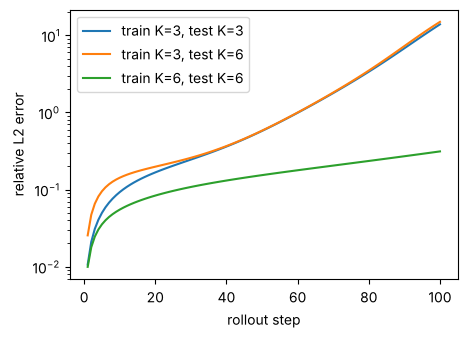

In [18]:
K_saved, K = K, 3
heat_train3 = np.stack([heat_trajectory() for _ in range(100)]).astype(np.float32)
heat_test3 = np.stack([heat_trajectory() for _ in range(20)]).astype(np.float32)
K = K_saved

torch.manual_seed(0)
model3 = train(SmallCNN(in_channels=1), DataLoader(to_pairs(heat_train3), batch_size=64, shuffle=True), epochs=10)
curves = {"train K=3, test K=3": heat_rollout_errors(model3, heat_test3),
          "train K=3, test K=6": heat_rollout_errors(model3, heat_test),
          "train K=6, test K=6": err1}
for name, c in curves.items():
    print(f"{name}:  step 1 {c[0]:.4f}   step 10 {c[9]:.3f}   step 100 {c[-1]:.3f}")
plt.figure(figsize=(5, 3.5))
for name, c in curves.items():
    plt.semilogy(np.arange(1, T + 1), c, label=name)
plt.xlabel("rollout step"); plt.ylabel("relative L2 error"); plt.legend(); plt.show()

**Answer.** On its own `K = 3` data the model is about as accurate for one step as the `K = 6` model. On `K = 6` data its one-step error is about 2.5 times larger: it never saw modes with $m$ or $n > 3$, which decay up to 4 times faster (the rate is proportional to $m^2 + n^2$), so it does not damp them correctly.

The rollout shows a larger problem: the `K = 3` model becomes unstable after about 40 steps on both test sets, even on `K = 3` data. Every step adds a small error, and some of it is at fine scales (high $m, n$). The `K = 6` model learned that fine scales decay quickly and damps that error. The `K = 3` model never saw fine scales decay, so the error grows instead. Training data that do not cover the scales the model will meet, including the scales of its own errors, cause both inaccuracy and instability.

### Exercise 4: frozen velocity

Same trained model; the velocity stays at its value at `start` for the whole rollout.

step  1   velocity from the simulation: 0.220   frozen velocity: 0.220
step  5   velocity from the simulation: 0.318   frozen velocity: 0.369
step 10   velocity from the simulation: 0.515   frozen velocity: 0.836
step 20   velocity from the simulation: 0.654   frozen velocity: 0.971
step 40   velocity from the simulation: 0.544   frozen velocity: 0.933
step 80   velocity from the simulation: 0.872   frozen velocity: 1.143


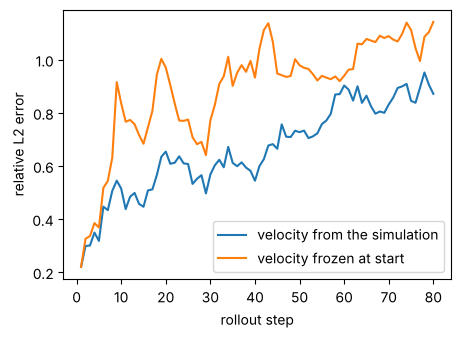

In [19]:
_, err_frozen = bubble_rollout(bubble_model, ["velx", "vely"], freeze=True)
for s in [1, 5, 10, 20, 40, 80]:
    print(f"step {s:2d}   velocity from the simulation: {err_base[s - 1]:.3f}   frozen velocity: {err_frozen[s - 1]:.3f}")
plt.figure(figsize=(5, 3.5))
plt.plot(np.arange(1, 81), err_base, label="velocity from the simulation")
plt.plot(np.arange(1, 81), err_frozen, label="velocity frozen at start")
plt.xlabel("rollout step"); plt.ylabel("relative L2 error"); plt.legend(); plt.show()

**Answer.** The prediction departs from the simulation within a few steps: in this run the error is already 0.84 at step 10 (0.52 with the velocity from the simulation) and stays near or above 1 after that. Temperature is carried by the flow. With the velocity frozen, the model keeps moving heat along the initial flow pattern while the bubbles and plumes in the simulation move on.

The model is only as good as the velocity it is given. A surrogate that runs on its own has to predict the velocity as well (Lecture 7).